# SwiftLog Week 5: Machine Learning Engineering

**Mission:** Intelligent Logistics Prediction & Supply Chain Optimization.

This notebook reviews source data, engineered features, exploratory analysis, candidate-model comparisons, evaluation artefacts, baseline comparisons, and limitations. The full training pipeline is `../run_swiftlog_project.py`. The supplied data is used as provided for this educational prototype. Results are reported as measured; weak performance is not hidden or described as production-ready.

## 1. Imports and paths

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path('..').resolve(); DATA=ROOT/'Data'; RAW=DATA/'Original_Datasets'; PROCESSED=DATA/'Processed_Datasets'; MODELS=ROOT/'Models'; REPORTS=ROOT/'Reports'
print('Project root:',ROOT)
print('Processed data:',PROCESSED.exists(),'Models:',MODELS.exists(),'Reports:',REPORTS.exists())

Project root: C:\Users\USER\Documents\SwiftLog-Machine-Learning-Engineering
Processed data: True Models: True Reports: True


## 2. Source data and quality checks

The source tables cover customers, orders, order items, products, shipments, delivery performance, returns, inventory, warehouses, suppliers, and employees. The original data dictionary is brief; engineered features are documented in `Feature_Data_Dictionary.csv`.

In [2]:
quality_path=PROCESSED/'data_quality_summary.csv'
if quality_path.exists(): display(pd.read_csv(quality_path))
else: print('Not found:',quality_path)
inventory=[]
for p in sorted(RAW.glob('*.csv')):
 d=pd.read_csv(p); inventory.append({'Dataset':p.name,'Rows':len(d),'Columns':len(d.columns),'Missing cells':int(d.isna().sum().sum()),'Duplicate rows':int(d.duplicated().sum())})
display(pd.DataFrame(inventory))

,Dataset,Rows,Columns,Duplicate rows,Missing cells,Missing columns
0,Customers,1000,3,0,0,NaN
1,Delivery_Performance,5000,3,0,0,NaN
2,Employees,200,2,0,0,NaN
3,Inventory,4000,3,3,0,NaN
4,Orders,5000,4,0,0,NaN
5,Order_Items,15000,4,0,0,NaN
6,Products,250,3,0,0,NaN
7,Returns,500,3,0,0,NaN
8,Shipments,5000,4,0,0,NaN
9,Suppliers,150,2,0,0,NaN


,Dataset,Rows,Columns,Missing cells,Duplicate rows
0,SwiftLog_Customers.csv,1000,3,0,0
1,SwiftLog_Data_Dictionary.csv,11,2,0,0
2,SwiftLog_Delivery_Performance.csv,5000,3,0,0
3,SwiftLog_Employees.csv,200,2,0,0
4,SwiftLog_Inventory.csv,4000,3,0,3
5,SwiftLog_Order_Items.csv,15000,4,0,0
6,SwiftLog_Orders.csv,5000,4,0,0
7,SwiftLog_Products.csv,250,3,0,0
8,SwiftLog_Returns.csv,500,3,0,0
9,SwiftLog_Shipments.csv,5000,4,0,0


## 3. Inspect the original target distributions

In [3]:
shipments=pd.read_csv(RAW/'SwiftLog_Shipments.csv'); returns=pd.read_csv(RAW/'SwiftLog_Returns.csv'); orders=pd.read_csv(RAW/'SwiftLog_Orders.csv')
delay_days=pd.to_numeric(shipments['DelayDays'],errors='coerce')
print('Shipments:',len(shipments)); print('Delayed shipments (DelayDays > 0):',int((delay_days>0).sum())); print('Orders associated with recorded returns:',returns['OrderID'].nunique()); print('Orders:',orders['OrderID'].nunique())
display(delay_days.describe().to_frame())

Shipments: 5000
Delayed shipments (DelayDays > 0): 4389
Orders associated with recorded returns: 473
Orders: 5000


,DelayDays
count,5000.00000
mean,3.56960
std,2.29142
min,0.00000
25%,2.00000
50%,4.00000
75%,6.00000
max,7.00000


## 4. Engineered feature samples

The delivery-delay target is `DelayDays > 0`. The return target is whether an order appears in the Returns table. Demand features use weekly product quantities and lagged prior-week values. Customer value is next-month revenue using the preceding three months of activity. Demand and customer-value evaluation uses chronological testing.

In [4]:
for title,filename in [('Delivery delay features','delivery_delay_features.csv'),('Product return features','product_return_features.csv'),('Weekly demand forecasting features','demand_forecasting_features.csv'),('Customer next-month value features','customer_value_features.csv')]:
 print(title); p=PROCESSED/filename
 if p.exists():
  d=pd.read_csv(p); print('Shape:',d.shape); display(d.head())
 else: print('Missing:',p)

Delivery delay features
Shape: (5000, 8)


,WarehouseID,Location,City,OrderDate_Year,OrderDate_Month,OrderDate_Day,OrderDate_Weekday,Target_Delayed
0,W10,Kano,Ibadan,2026,7,22,2,0
1,W03,Abuja,Lagos,2026,4,11,5,1
2,W07,Lagos,Lagos,2026,1,7,2,0
3,W05,Lagos,Abuja,2026,1,30,4,0
4,W06,Lagos,Kano,2026,5,16,5,1


Product return features
Shape: (5000, 11)


,City,OrderDate_Year,OrderDate_Month,OrderDate_Day,OrderDate_Weekday,ItemCount,TotalQuantity,DistinctProducts,TotalRevenue,MeanUnitPrice,Target_Returned
0,Ibadan,2026,7,22,2,7.0,34.0,7.0,8273.72,221.988571,0
1,Lagos,2026,4,11,5,5.0,35.0,5.0,7330.27,225.812000,0
2,Lagos,2026,1,7,2,3.0,19.0,3.0,4713.13,296.120000,0
3,Abuja,2026,1,30,4,3.0,18.0,3.0,5903.11,329.630000,0
4,Kano,2026,5,16,5,3.0,16.0,3.0,3026.48,221.593333,0


Weekly demand forecasting features


Shape: (8250, 11)


,ProductID,Category,UnitPrice,Year,Month,DayOfWeek,Lag_1_Week,Lag_4_Weeks,Rolling_Mean_4_Weeks,DemandQuantity,WeekStart
0,P001,Electronics,248.85,2026,1,0,0.0,9.0,11.50,11.0,2026-01-26
1,P002,Fashion,177.08,2026,1,0,36.0,0.0,11.25,9.0,2026-01-26
2,P003,Food,358.11,2026,1,0,0.0,4.0,5.00,21.0,2026-01-26
3,P004,Electronics,487.85,2026,1,0,8.0,4.0,5.75,0.0,2026-01-26
4,P005,Electronics,20.62,2026,1,0,3.0,15.0,6.50,0.0,2026-01-26


Customer next-month value features


Shape: (6000, 13)


,CustomerID,MonthStart,MonthRevenue,MonthQuantity,MonthItems,MonthAvgUnitPrice,MonthOrders,Previous_3M_Revenue,Previous_3M_Order_Count,Previous_3M_Quantity,Previous_3M_Item_Count,Previous_3M_Avg_Unit_Price,City
0,C0001,2026-04-01,0.0,0.0,0.0,NaN,0.0,1269.29,2.0,3.0,2.0,NaN,Abuja
1,C0002,2026-04-01,0.0,0.0,0.0,NaN,0.0,6624.25,2.0,23.0,5.0,NaN,Lagos
2,C0003,2026-04-01,0.0,0.0,0.0,NaN,0.0,0.00,1.0,0.0,0.0,NaN,Ibadan
3,C0004,2026-04-01,0.0,0.0,0.0,NaN,0.0,4898.25,1.0,20.0,3.0,NaN,Lagos
4,C0005,2026-04-01,0.0,0.0,0.0,NaN,0.0,559.82,2.0,4.0,2.0,NaN,Kano


## 5. Compare the candidate algorithms

Three algorithms were compared for each task. `Selected` marks the model stored in `Best_Model.pkl`; `Tuned` indicates that a tuning search was accepted.

In [5]:
comparison=pd.read_excel(MODELS/'Model_Comparison.xlsx'); display(comparison); display(comparison[comparison['Selected']==True])

,Problem,Algorithm,Rows,Features,Selected,Tuned,Accuracy,Precision,Recall,F1,ROC_AUC,MAE,RMSE,R2
0,Delivery Delay Classification,Random Forest (tuned),5000,7,True,True,0.829,0.882990,0.928246,0.905053,0.511894,NaN,NaN,NaN
1,Delivery Delay Classification,Decision Tree,5000,7,False,False,0.542,0.876344,0.556948,0.681058,0.486645,NaN,NaN,NaN
2,Delivery Delay Classification,Logistic Regression,5000,7,False,False,0.523,0.871985,0.535308,0.663373,0.475447,NaN,NaN,NaN
3,Product Return Classification,Logistic Regression,5000,10,True,False,0.538,0.098468,0.473684,0.163043,0.487595,NaN,NaN,NaN
4,Product Return Classification,Decision Tree,5000,10,False,False,0.421,0.085616,0.526316,0.147275,0.475731,NaN,NaN,NaN
5,Product Return Classification,Random Forest,5000,10,False,False,0.880,0.096774,0.031579,0.047619,0.508962,NaN,NaN,NaN
6,Product Demand Forecasting,Random Forest Regressor (tuned),8250,9,True,True,NaN,NaN,NaN,NaN,NaN,6.523835,8.077778,-0.013980
7,Product Demand Forecasting,Decision Tree Regressor,8250,9,False,False,NaN,NaN,NaN,NaN,NaN,6.657536,8.485197,-0.118843
8,Product Demand Forecasting,Linear Regression,8250,9,False,False,NaN,NaN,NaN,NaN,NaN,6.612885,8.205115,-0.046200
9,Customer Value Prediction (Next Month),Linear Regression,6000,6,True,False,NaN,NaN,NaN,NaN,NaN,2990.706373,3757.004105,-0.068606


,Problem,Algorithm,Rows,Features,Selected,Tuned,Accuracy,Precision,Recall,F1,ROC_AUC,MAE,RMSE,R2
0,Delivery Delay Classification,Random Forest (tuned),5000,7,True,True,0.829,0.882990,0.928246,0.905053,0.511894,NaN,NaN,NaN
3,Product Return Classification,Logistic Regression,5000,10,True,False,0.538,0.098468,0.473684,0.163043,0.487595,NaN,NaN,NaN
6,Product Demand Forecasting,Random Forest Regressor (tuned),8250,9,True,True,NaN,NaN,NaN,NaN,NaN,6.523835,8.077778,-0.013980
9,Customer Value Prediction (Next Month),Linear Regression,6000,6,True,False,NaN,NaN,NaN,NaN,NaN,2990.706373,3757.004105,-0.068606


## 6. Review selected-model evaluation visuals

delivery_delay_classification_confusion_matrix.png


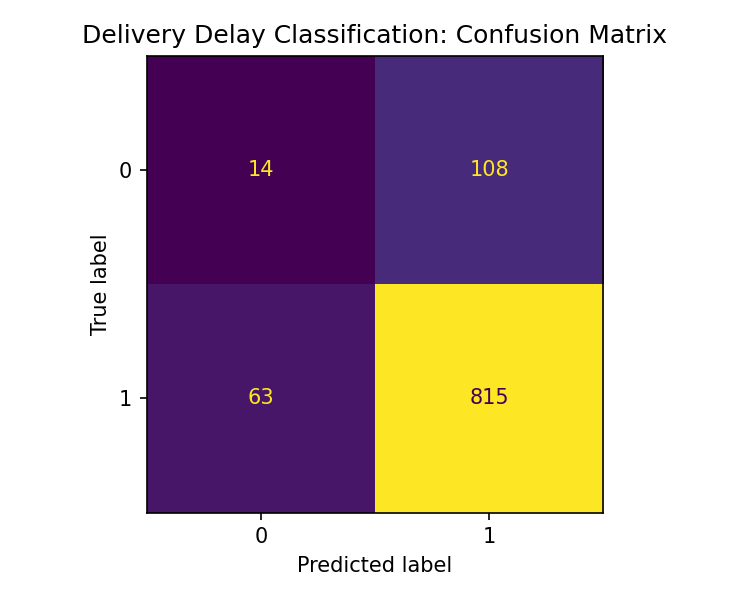

product_return_classification_confusion_matrix.png


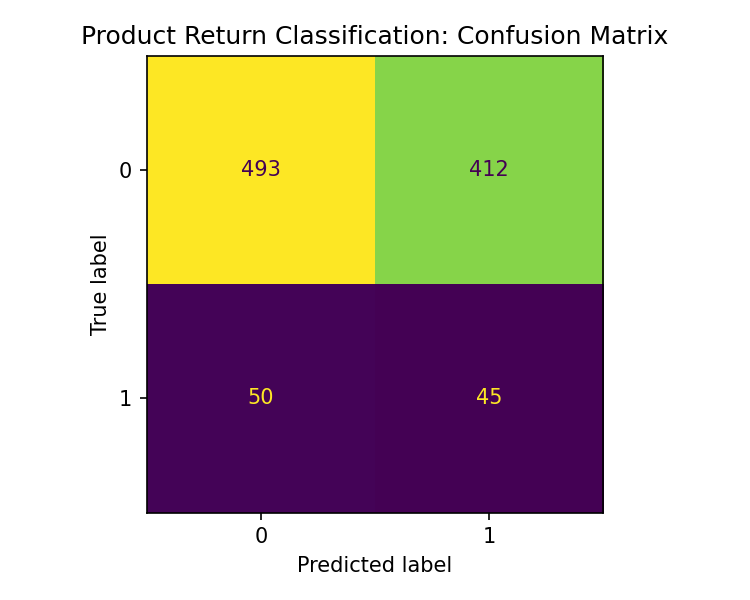

Feature importance


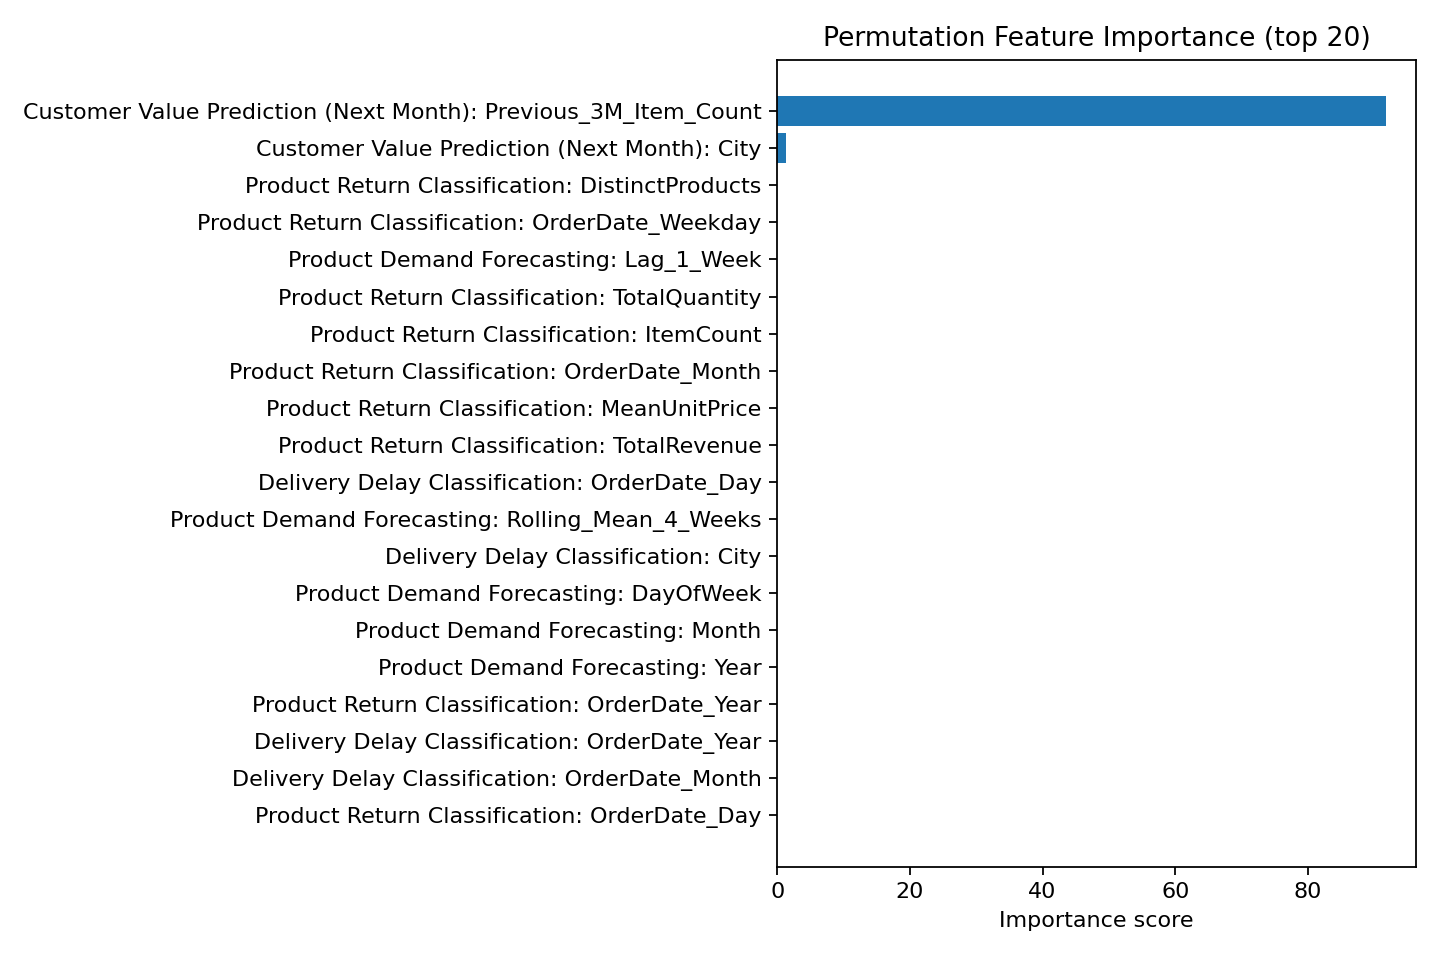

In [6]:
for name in ['delivery_delay_classification_confusion_matrix.png','product_return_classification_confusion_matrix.png']:
 p=MODELS/name
 if p.exists(): print(name); display(Image(filename=str(p)))
p=MODELS/'Feature_Importance.png'
if p.exists(): print('Feature importance'); display(Image(filename=str(p)))

## 7. Supplementary exploratory data analysis

Run `python enhance_swiftlog_eda.py` from the project root to create missing-value summaries, numeric distributions, correlation heatmaps where possible, target distribution charts, and IQR-based outlier summaries.

Not available: eda_missing_values.png
eda_target_delivery_delay.png


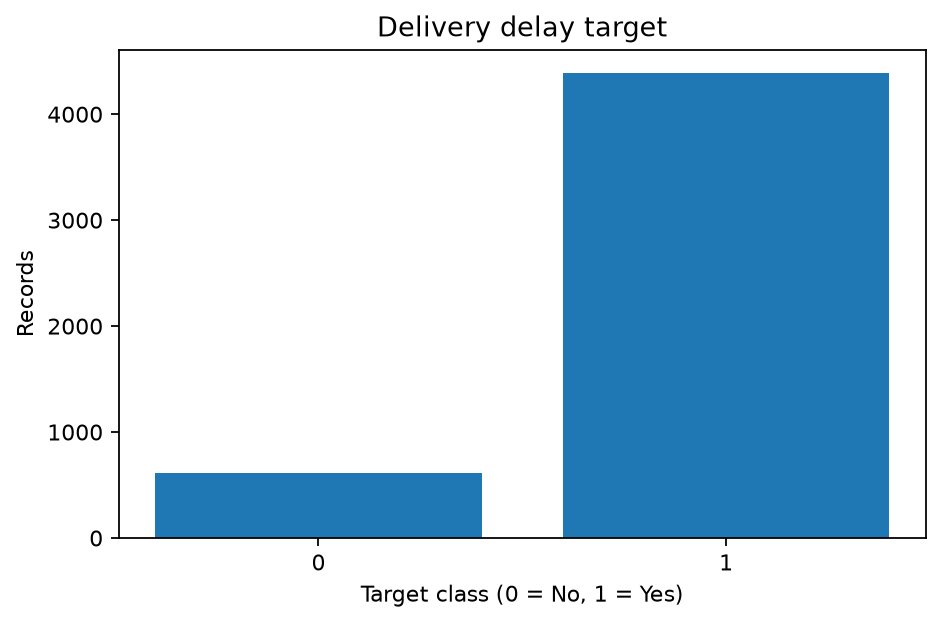

eda_target_product_return.png


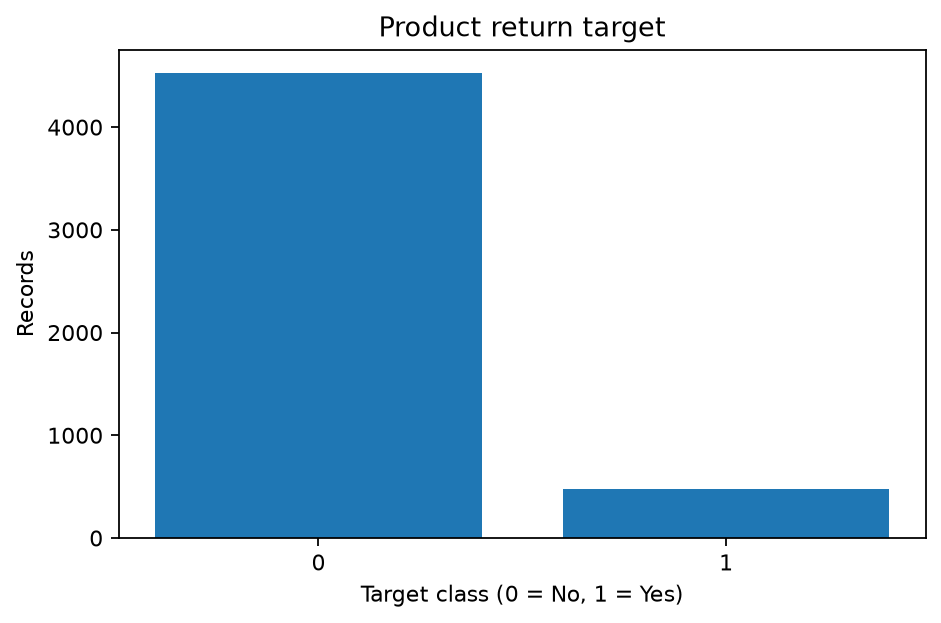

eda_missing_values_by_column.csv


,Dataset,Column,Rows,Missing_Count,Missing_Percent
0,SwiftLog_Customers,CustomerID,1000,0,0.0
1,SwiftLog_Customers,CustomerName,1000,0,0.0
2,SwiftLog_Customers,City,1000,0,0.0
3,SwiftLog_Data_Dictionary,File,11,0,0.0
4,SwiftLog_Data_Dictionary,Description,11,0,0.0
5,SwiftLog_Delivery_Performance,ShipmentID,5000,0,0.0
6,SwiftLog_Delivery_Performance,Status,5000,0,0.0
7,SwiftLog_Delivery_Performance,DelayDays,5000,0,0.0
8,SwiftLog_Employees,EmployeeID,200,0,0.0
9,SwiftLog_Employees,WarehouseID,200,0,0.0


eda_numeric_outlier_summary.csv


,Dataset,Column,Non_Missing_Values,Outlier_Count_IQR,Outlier_Percent,Median,Q1,Q3
0,SwiftLog_Delivery_Performance,DelayDays,5000,0,0.0,4.000,2.00,6.00
1,SwiftLog_Inventory,Stock,4000,0,0.0,253.000,131.00,373.00
2,SwiftLog_Order_Items,Quantity,15000,0,0.0,6.000,3.00,8.00
3,SwiftLog_Products,UnitPrice,250,0,0.0,263.565,143.98,391.62
4,SwiftLog_Shipments,DelayDays,5000,0,0.0,4.000,2.00,6.00


In [7]:
for name in ['eda_missing_values.png','eda_target_delivery_delay.png','eda_target_product_return.png']:
 p=REPORTS/name
 if p.exists(): print(name); display(Image(filename=str(p)))
 else: print('Not available:',name)
for name in ['eda_missing_values_by_column.csv','eda_numeric_outlier_summary.csv']:
 p=REPORTS/name
 if p.exists():
  d=pd.read_csv(p); print(name); display(d.head(20))
 else: print('Not available:',name)

eda_distribution_swiftlog_delivery_performance_delaydays.png


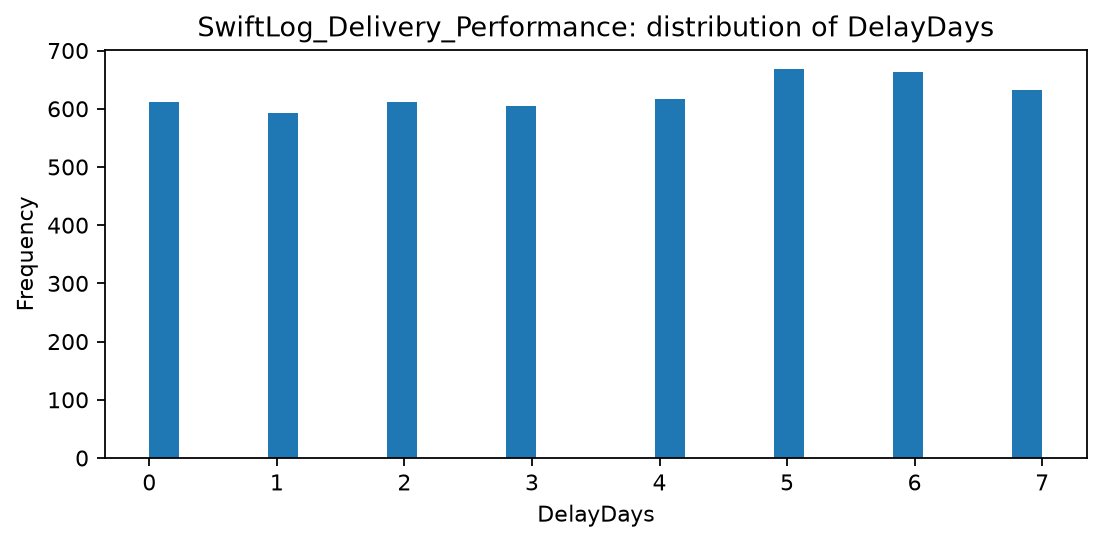

eda_distribution_swiftlog_inventory_stock.png


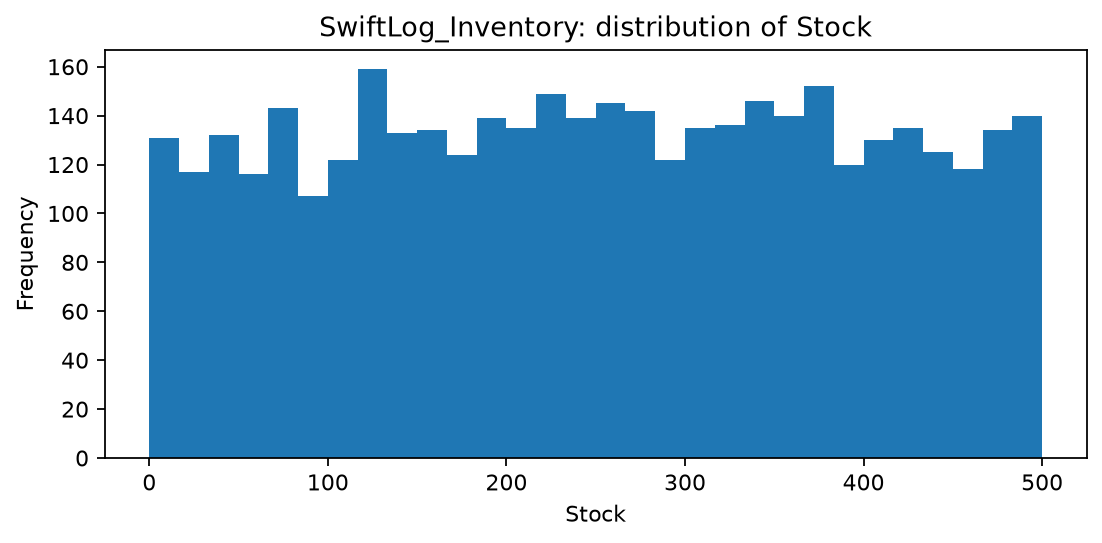

eda_distribution_swiftlog_order_items_quantity.png


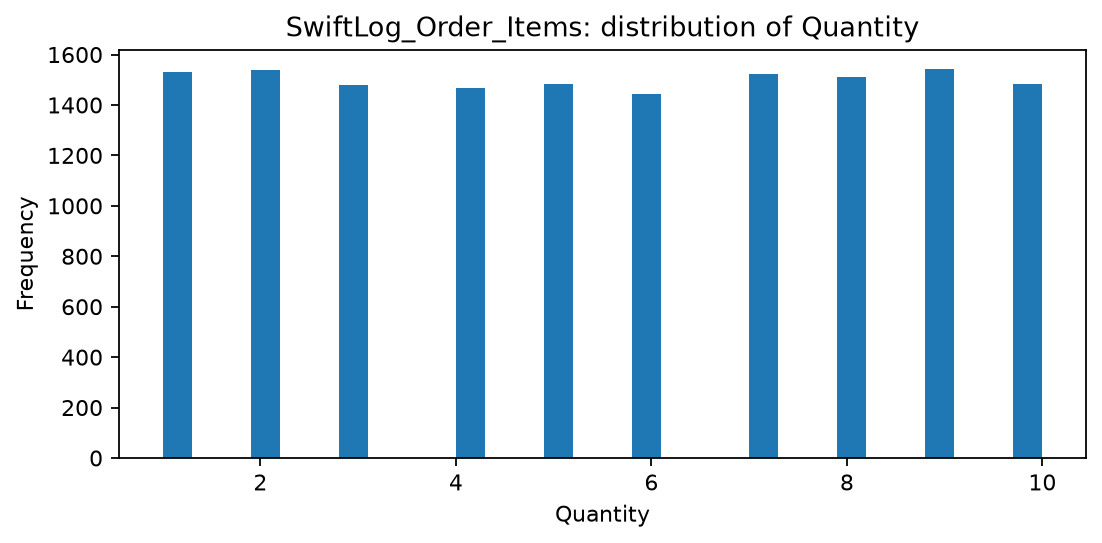

eda_distribution_swiftlog_products_unitprice.png


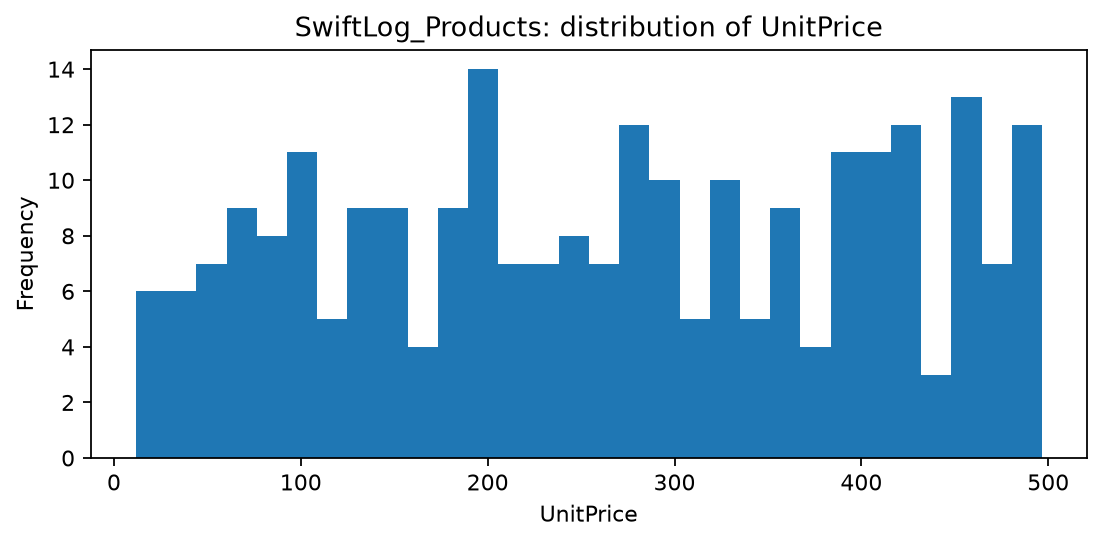

eda_distribution_swiftlog_shipments_delaydays.png


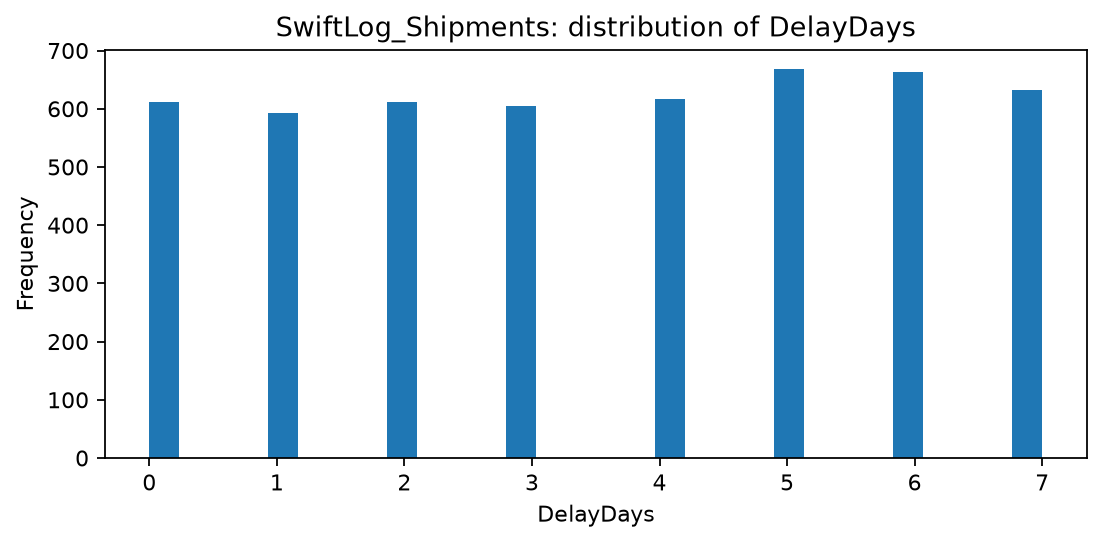

In [8]:
figures=sorted(list(REPORTS.glob('eda_correlation_*.png'))+list(REPORTS.glob('eda_distribution_*.png')))
for p in figures: print(p.name); display(Image(filename=str(p)))
if not figures: print('No additional correlation/distribution images found yet.')

## 8. Baseline comparisons

Classification baselines predict the majority class in the training partition. Regression baselines predict the mean target value from the training period. The supplementary script constructs its own splits; unless test rows are confirmed identical, these are supplementary benchmarks rather than strict like-for-like comparisons.

In [9]:
p=REPORTS/'Baseline_Comparison.csv'
if p.exists(): baseline=pd.read_csv(p); display(baseline)
else: print('Baseline comparison not found. Run enhance_swiftlog_eda.py.')
cols=[c for c in ['Problem','Algorithm','Selected','Tuned','Accuracy','Precision','Recall','F1','ROC_AUC','MAE','RMSE','R2'] if c in comparison.columns]
display(comparison.loc[comparison['Selected']==True,cols])

,Problem,Baseline,Test_Rows,Accuracy,Precision,Recall,F1,MAE,RMSE,R2
0,Delivery Delay Classification,Training-set majority class,1000,0.878,0.878,1.0,0.935037,NaN,NaN,NaN
1,Product Return Classification,Training-set majority class,1000,0.905,0.000,0.0,0.000000,NaN,NaN,NaN
2,Product Demand Forecasting,Training-period mean,1750,NaN,NaN,NaN,NaN,6.545177,8.054406,-0.008120
3,Customer Value Prediction (Next Month),Training-period mean,2000,NaN,NaN,NaN,NaN,2987.088442,3747.890533,-0.063428


,Problem,Algorithm,Selected,Tuned,Accuracy,Precision,Recall,F1,ROC_AUC,MAE,RMSE,R2
0,Delivery Delay Classification,Random Forest (tuned),True,True,0.829,0.882990,0.928246,0.905053,0.511894,NaN,NaN,NaN
3,Product Return Classification,Logistic Regression,True,False,0.538,0.098468,0.473684,0.163043,0.487595,NaN,NaN,NaN
6,Product Demand Forecasting,Random Forest Regressor (tuned),True,True,NaN,NaN,NaN,NaN,NaN,6.523835,8.077778,-0.013980
9,Customer Value Prediction (Next Month),Linear Regression,True,False,NaN,NaN,NaN,NaN,NaN,2990.706373,3757.004105,-0.068606


## 9. Interpretation and limitations

- **Delivery delay:** selected Random Forest accuracy is about 0.829, F1 about 0.905, and ROC-AUC about 0.512. The supplementary majority-class baseline achieved 0.878 accuracy and F1 about 0.935, so the selected model did not beat that baseline on those measures. ROC-AUC indicates weak discrimination.
- **Product returns:** selected Logistic Regression F1 is about 0.163 and ROC-AUC about 0.488. The majority-class baseline achieved 0.905 accuracy but zero positive-class precision, recall, and F1. Accuracy alone is misleading here.
- **Weekly demand:** selected-model R-squared is about -0.014. The mean baseline had MAE 6.545, RMSE 8.054, and R-squared -0.008. The selected model's MAE is slightly lower, but RMSE and R-squared are worse.
- **Customer value:** selected-model R-squared is about -0.069. The mean baseline had MAE 2,987.088, RMSE 3,747.890, and R-squared -0.063, better than the selected model on these measures.
- **Data limitations:** limited history; supplier IDs are not linked directly to shipments; warehouse capacity is absent; inventory records lack time-stamped snapshots.

Model outputs should support human review only. They are not validated for live logistics decisions. Baseline comparisons are supplementary because identical test rows have not been verified.

## 10. Reproduce the outputs

From the project root, run `python run_swiftlog_project.py` to regenerate processed data, features, model comparisons, saved model bundles, evaluation figures, reports, and presentation. This may overwrite generated outputs. Run `python enhance_swiftlog_eda.py` to regenerate supplementary EDA and baseline files, then rerun this notebook.